# Fresnel Lens Phase-Shifting Holography


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：phase_shifting_holography

**观测 y：** holograms(1, 4, 1024, 1024)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 双实通道物体与参考复交叉项(DN)。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** 四相移干涉强度为物波和相移参考波之和的模平方。本地路径为 `solvers.reconstruct→quadrature及carrier搜索`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 8, 9（cell编号按文件内从0计）。章节包括：# Fresnel Lens Phase-Shifting Holography；## 1. Problem；## 2. Data；## 3. Physics；## 4. Method；## 5. Results；## 6. Conclusion。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 交叉项不能当绝对高度；无独立光场GT。

<!-- inverse-evidence-audit:20261026:end -->



## Current benchmark evaluation (v2, 2026-10-29)

V2 verifies the measured full complex quadrature up to a unit linear reference-tilt gauge fixed at the half-array origin. Earlier fixed-carrier NCC/NRMSE and finite-search comparisons remain historical v1 reproduction diagnostics; the four frames do not uniquely calibrate reference tilt.

The reconstruction and scientific comparisons below retain the validated original-method path. Current Judge calls use the unchanged standalone interface and return a status/metrics report; historical comparison metrics are labeled separately.

## 1. Problem

Recover a compensated complex camera-plane interferometric cross-term from four real phase-shifted Fresnel-lens frames. Both amplitude and phase are required, with the factor-four scale and fixed phase origin preserved.

Active maintainer reconstruction and independently identified scientific comparisons.


Recover the compensated **complex camera-plane cross-term** of a Fresnel lens
from four experimentally phase-shifted intensity frames. The reference advances
by nominal pi/2 steps; DC intensity, the twin interference term, a tilted
reference and lossy export all obscure the object phase. This is the selected
slightly off-axis SOSR experiment of Castaneda et al. (2022), DOI
10.1371/journal.pone.0275818, section 3.2 / Fig. 4. It does not include blind
USAF algorithms, another specimen or an unexecuted propagation experiment.

The submission is `output/reconstruction.npz`, key `reconstruction`, real
float32/float64 shape **(1,2,1024,1024)**: batch, component, row, column. Component 0
is Re(C), component 1 Im(C), both DN. Keep the factor four, frame order, full-frame
mean convention and phase origin; do not normalize, divide by four, crop, rotate
phase, conjugate or remove another plane. Both phase and amplitude are required.
There is no independently measured true complex wave, absolute optical power,
object magnification or lens-height calibration. We compare an independent
original-method run with an actively recomputed local implementation.


## 2. Data

The four complete 1024-square uint8 images are released JPEG grayscale exports despite BMP filenames. Wavelength is 632.8 nm and camera pitch 6.9 micrometres; unknown absolute irradiance, magnification and lens-height calibration prevent a true object-height interpretation.


The exact observations are `data/phase-shifting samples/cut_samples/I0_Fresnel_Lens.bmp` through `I3_Fresnel_Lens.bmp` in
https://github.com/catrujilla/pyDHM at remotely verified commit
`e8cbb1e1ce5007c0f2b65d9b7ce2a4962915f8cc`. The published paper identifies
the real experimental Fresnel lens and liquid-lens quarter-cycle stepping.
Despite the .bmp suffix these are JPEG RGB exports. The upstream MATLAB helper
documents an earlier crop/mat2gray/uint8/JPEG export route; the exact uncropped
sensor originals are not available. Conversion follows the upstream grayscale
reader, preserving released 1024-square grayscale pixels with no new crop,
resize, normalization or noise injection. The archived independent original
SOSR output and original run JSON are loaded only for labeled maintainer
comparison, not as solver inputs or truth.

No independent physical irradiance or object-plane magnification calibration
is available.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| holograms | (1, 4, 1024, 1024) | uint8 | Four quarter-cycle phase-shifted measured intensities in DN, ordered phase 0, pi/2, pi, 3pi/2; axes batch, phase, row, column. |


## 3. Physics

Nominal frames obey $I_j=|O+Re^{ij\pi/2}|^2+\epsilon_j$, with amplitudes $O,R$ in square-root DN. After full-frame mean subtraction, the combination $Q=H_0+iH_1-H_2-iH_3$ cancels DC/twin terms while retaining the declared factor four. Multiplication by a unit-modulus digital reference compensates the selected carrier without changing amplitude scale.

Four experimentally acquired frames image the same Fresnel lens while the
reference phase advances by a quarter cycle. At each camera pixel the ideal
interference model is


$$
I_j(y,x)=|O(y,x)+R(y,x)\exp(i j\pi/2)|^2+\epsilon_j(y,x),\qquad j=0,1,2,3.
$$


Here I denotes recorded intensity in digital numbers (DN), O is the object
wave, R is the tilted reference wave, i is the imaginary unit, and epsilon
includes noise, encoding error and experimental model mismatch. Indices x and y
increase along columns and rows. O and R have amplitude units sqrt(DN) under
this idealized intensity convention; their individual physical irradiance is
not calibrated. The reference is approximately a plane wave. The inverse
problem is to separate a complex object-reference cross-term from real
intensities and determine the reference tilt. Absolute object height and an
absolute optical phase origin are not supplied by this acquisition.


For object/reference amplitudes O and R in sqrt(DN), nominal frame j records
I_j=|O+R exp(ij*pi/2)|^2+epsilon_j in DN. The error includes experimental
phase-step departures and image encoding. Expansion gives DC intensity plus
O*conj(R) exp(-ij*pi/2) and its conjugate. Multiplying frames by i^j and
summing cancels both DC and the conjugate term, leaving 4O*conj(R).

Let H_j=I_j-mean(I_j), with the mean over the entire camera window. Then


$$
Q=H_0+iH_1-H_2-iH_3
=4\left(O\overline R-\langle O\overline R\rangle\right)
\quad\hbox{in the noiseless model},\qquad C=R_dQ.
$$


Here Q is uncompensated and C compensated, both DN. For rows M, columns N,
half-array coordinates X=x-N/2, Y=y-M/2 and candidate bins fx, fy,


$$
R_d=\exp\left[2\pi i\left((N/2-f_x)X/N+(M/2-f_y)Y/M\right)\right].
$$


The executable equivalent computes angles asin((N/2-fx)*lambda/(N*dx))
and asin((M/2-fy)*lambda/(M*dy)), then the phasor with 2pi/lambda.
Lambda = 632.8e-9 m and pitches = 6.9e-6 m cancel algebraically; |R_d|=1.
This fixes sign and phase origin without calibration of absolute optical power.
The centered carrier spectrum is fftshift(fft2(fftshift(H0))), negative
exponential, unnormalized. Its finite 1024-square window has periodic DFT
extension, no taper/padding. No spatial propagation or height inverse is run.


## 4. Method

The local source performs full-frame centering, exact source-ROI carrier argmax and finite exhaustive digital-reference search. Search ties, coordinate origin and finite DFT extension remain fixed; no propagation or arbitrary phase rotation follows the selected SOSR inverse.


Promote stored uint8 to float64; subtract each frame's full spatial mean.
Initialize (fx, fy) by the first power argmax in the literal upstream ROI:
rows 1:int(M/2)-int(M-.1M), columns 1:N. With M=1024 its negative stop includes
rows 1..614, wider than a strict upper half. Preserve this convention and check
independently that the bound peak agrees with the strict-upper alternative.
Using power instead of its monotonic log avoids log(0) without changing argmax.

Use s=1 bin, steps=4: x in linspace(fx-s,fx+s,4) as outer loop, y analogously
as inner. For each of 16 candidates compute C with the exact ordered quadrature
and reference multiplications, phi=angle(C), then count
(phi-min(phi))/(max(phi)-min(phi))<.1. Maximize that integer score; strict-greater
updates retain the first tied maximum. A zero-span phase returns score zero,
but every bound candidate has nonzero span. Stop after all 16 candidates and
recompute selected C. There is no gradient, regularizer, continuous optimizer,
training, line search or residual stopping rule in this finite inverse.

The Results cells actively recover all 1024-square observations. The independent
original output is comparison-only. Evaluate both real channels at fixed scale:
uncentered NCC>=.9999999999 and dynamic-range NRMSE <= 6.6583485927655845e-8.
The latter is 10 times independently measured original float32-input sensitivity,
fixed before extraction. These are method reproduction tolerances, not physical
height accuracy. Independent quadrature/phase-sign/Parseval/amplitude checks
complement agreement and are preserved in tests.


## 5. Results

The active all-frame reconstruction is compared with an independent original-method run through complex maps, uncompensated/compensated phase, amplitude, spectral carrier diagnostics and metrics. Lossy image export and phase-step departures can leave residual model mismatch.

### Acquisition metadata

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Illumination wavelength | 632.8e-9 | m | Illumination value supplied with the experimental example. |
| Camera pitch x | 6.9e-6 | m/pixel | Sensor column spacing. |
| Camera pitch y | 6.9e-6 | m/pixel | Sensor row spacing. |
| Frame phase increments | pi/2 | rad | Nominal reference phase increase between adjacent frames, introduced using a liquid lens. |
| Image rows and columns | 1024 by 1024 | pixel | Released spatial extent; no additional padding. |
| Frame count | 4 | dimensionless | Same sample and nominal geometry. |
| Pixel coordinate origin | x = column - N/2; y = row - M/2 | pixel | Half-array-centered coordinates, not (N-1)/2. Rows increase downward. |
| Diffraction order | upper half-plane | dimensionless | Select the upper object-order peak, excluding the central DC order. |
| Discrete transform | negative exponential, no forward normalization | dimensionless | Forward FFT uses a pre-shift and a post-shift; full finite camera window, no taper or padding. |
| Boundary convention | finite camera window; periodic DFT extension | dimensionless | Applies only to spectral carrier estimation; no spatial propagation. |
| Noise calibration | not supplied | DN | No calibrated likelihood or known Gaussian noise variance is assumed. |
| Physical scale | released 8-bit grayscale intensity | DN | Upstream image exports; no conversion to optical power or lens thickness. |


Every fresh reconstruction and comparison here is computed from the loaded real
observations using local src modules. Independent original-code outputs are
labeled references, never physical truth. Previously packaged snapshots are
kept byte-frozen; this execution's runtime and evidence are captured privately.
Display normalization affects figure contrast only, not quantitative arrays.

### Fresh complete selected reconstruction


### Measured spectrum and every finite carrier candidate


### Fresh raw/compensated phase, independent original phase, amplitude and complex error


### Paired original/fresh metrics and independent amplitude/strict-upper checks


In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').exists()
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations,center_frames
from src.physics_model import centered_spectrum,quadrature,phase_score,reference_wave
from src.solvers import reconstruct
from src.visualization import comparison_plot,metrics
holograms=load_observations(ROOT/'data/raw_data.npz')
upstream_info=json.loads((ROOT/'notebooks/reference_outputs/upstream_measurements.json').read_text())
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as z:
    upstream_channels=z['reconstruction']
upstream=upstream_channels[0,0]+1j*upstream_channels[0,1]
print('Data:',holograms.shape,'DN; stored uint8, computed',holograms.dtype)
print('Bound data SHA256:',upstream_info['raw_sha256'])
print('Upstream revision:',upstream_info['revision'])
with np.load(ROOT/'data/raw_data.npz',allow_pickle=False) as visible:
    print('Visible acquisition arrays (batch first on disk):')
    for key in visible.files: print(key,visible[key].shape,str(visible[key].dtype))


Data: (4, 1024, 1024) DN; stored uint8, computed float64
Bound data SHA256: 6f1044c71141990dfa8ac03ed7bf6c5f336725f88f97b5fe6b23f00bc6994ea8
Upstream revision: e8cbb1e1ce5007c0f2b65d9b7ce2a4962915f8cc
Visible acquisition arrays (batch first on disk):
holograms (1, 4, 1024, 1024) uint8


In [2]:
start=time.perf_counter()
fresh,info=reconstruct(holograms)
runtime=time.perf_counter()-start
fresh_channels=np.stack([fresh.real,fresh.imag])[None]
measured=metrics(fresh_channels,upstream_channels)
fresh_record=dict(method='fresh local SOSR',runtime_seconds=runtime,**measured,**info,
                  data_sha256=upstream_info['raw_sha256'],reference='separate upstream SOSR execution')
print(json.dumps(fresh_record,indent=2))
assert measured['ncc_vs_ref']>=.9999999999
assert measured['nrmse_vs_ref']<=6.6583485927655845e-8

{
  "method": "fresh local SOSR",
  "runtime_seconds": 1.3481434000423178,
  "ncc_vs_ref": 1.0,
  "nrmse_vs_ref": 0.0,
  "carrier": [
    513.6666666666666,
    467.6666666666667
  ],
  "score": 156192,
  "peak": [
    514,
    468
  ],
  "candidates": 16,
  "data_sha256": "6f1044c71141990dfa8ac03ed7bf6c5f336725f88f97b5fe6b23f00bc6994ea8",
  "reference": "separate upstream SOSR execution"
}


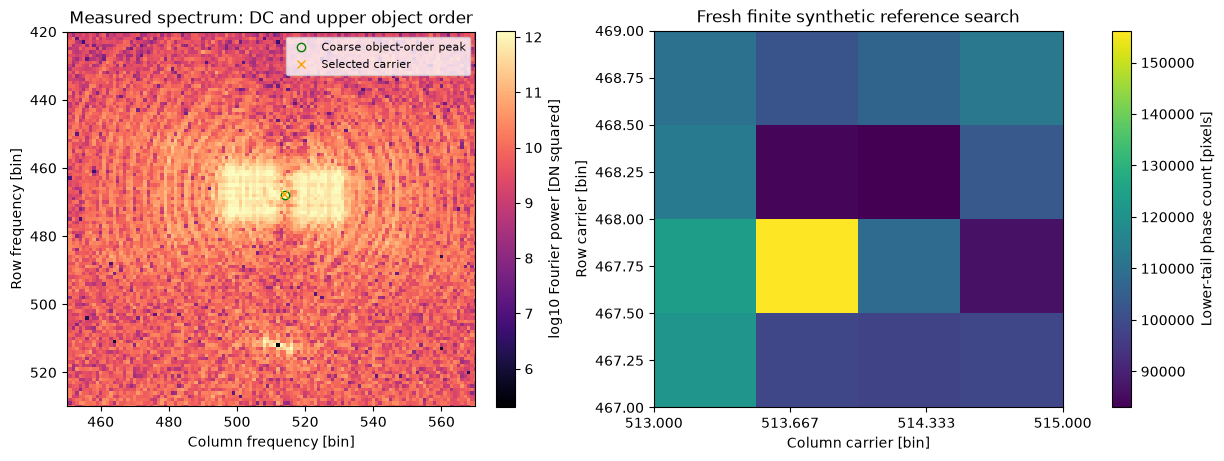

In [3]:
centered=center_frames(holograms)
spectrum=centered_spectrum(centered[0])
fig,axs=plt.subplots(1,2,figsize=(12,4.5),constrained_layout=True)
logpower=np.log10(np.maximum(abs(spectrum)**2,np.finfo(float).tiny))
im=axs[0].imshow(logpower,cmap='magma',vmin=np.percentile(logpower,5),vmax=np.percentile(logpower,99.99)); fig.colorbar(im,ax=axs[0],label='log10 Fourier power [DN squared]')
axs[0].plot(*info['peak'],'go',fillstyle='none',label='Coarse object-order peak')
axs[0].plot(*info['carrier'],'x',color='orange',label='Selected carrier')
axs[0].set(xlim=(450,570),ylim=(530,420),title='Measured spectrum: DC and upper object order',xlabel='Column frequency [bin]',ylabel='Row frequency [bin]')
axs[0].legend(fontsize=8)
xs=np.linspace(info['peak'][0]-1,info['peak'][0]+1,4)
ys=np.linspace(info['peak'][1]-1,info['peak'][1]+1,4)
scores=np.array([[phase_score(quadrature(centered,reference_wave(centered.shape[1:],x,y))) for x in xs] for y in ys])
im=axs[1].imshow(scores,origin='lower',extent=(xs[0],xs[-1],ys[0],ys[-1]),cmap='viridis',aspect='auto')
fig.colorbar(im,ax=axs[1],label='Lower-tail phase count [pixels]')
axs[1].set(title='Fresh finite synthetic reference search',xlabel='Column carrier [bin]',ylabel='Row carrier [bin]')
axs[1].set_xticks(xs,labels=[f'{x:.3f}' for x in xs])
plt.show()

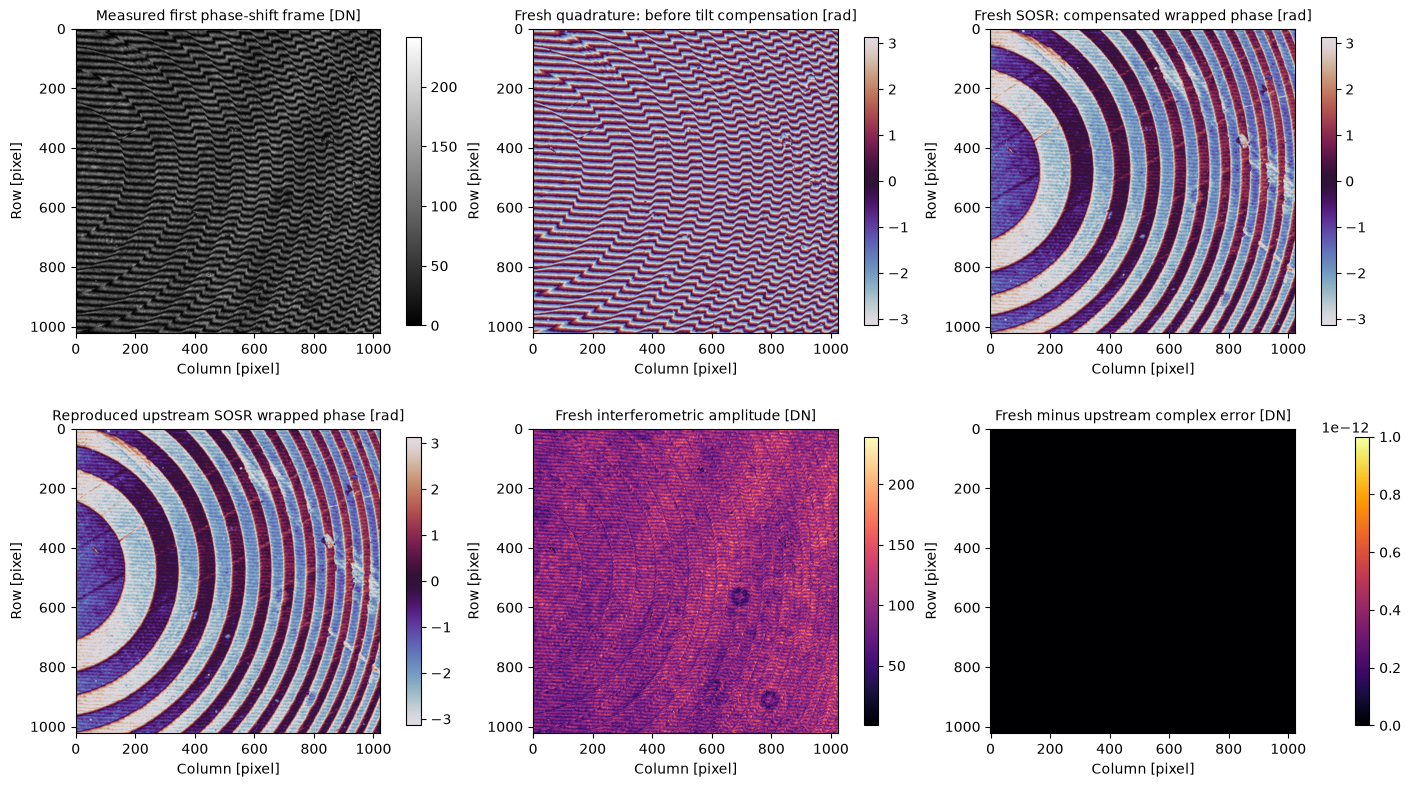

In [4]:
uncompensated=quadrature(centered,np.ones(holograms.shape[1:]))
fig=comparison_plot(holograms,fresh,upstream,uncompensated)
plt.show()

In [5]:
display(Markdown('| Measurement | NCC vs upstream | Dynamic-range NRMSE | Runtime [s] |\n| --- | ---: | ---: | ---: |\n'
    +f'| Reproduced upstream SOSR (independent repeated run) | 1 | 0 | {upstream_info["runtime_seconds"]:.6f} |\n'
    +f'| Fresh local SOSR | {measured["ncc_vs_ref"]:.12g} | {measured["nrmse_vs_ref"]:.12g} | {runtime:.6f} |'))
expected_amplitude=np.hypot(centered[0]-centered[2],centered[1]-centered[3])
physical_residual=np.linalg.norm(abs(fresh)-expected_amplitude)/np.linalg.norm(expected_amplitude)
print('Unit-reference amplitude conservation relative L2 residual:',physical_residual)
assert physical_residual<1e-13
peak_upper=np.unravel_index(np.argmax(abs(spectrum[1:512,1:])**2),spectrum[1:512,1:].shape)
assert tuple(info['peak'])==(peak_upper[1]+1,peak_upper[0]+1)
print('Independent strict-upper peak check passed')

| Measurement | NCC vs upstream | Dynamic-range NRMSE | Runtime [s] |
| --- | ---: | ---: | ---: |
| Reproduced upstream SOSR (independent repeated run) | 1 | 0 | 3.253032 |
| Fresh local SOSR | 1 | 0 | 1.348143 |

Unit-reference amplitude conservation relative L2 residual: 1.2797180549466623e-16
Independent strict-upper peak check passed


In [6]:
import importlib.util
(ROOT/'output').mkdir(exist_ok=True)
np.savez_compressed(ROOT/'output/reconstruction.npz',reconstruction=fresh_channels)
spec=importlib.util.spec_from_file_location('independent_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exit_code=judge.evaluate(ROOT/'output/reconstruction.npz')
print(json.dumps(report,indent=2));assert exit_code==0
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2),encoding='utf8')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc_vs_ref": 1.0,
    "nrmse_vs_ref": 0.0
  },
  "thresholds": {
    "ncc_vs_ref": {
      "comparison": ">=",
      "boundary": 0.9999999999
    },
    "nrmse_vs_ref": {
      "comparison": "<=",
      "boundary": 6.658348592765584e-08
    }
  },
  "errors": []
}


324

## 6. Conclusion

The retained comparison supports the selected camera-plane quadrature/reference-search extraction. It does not measure a true optical field, calibrated optical power or Fresnel-lens height, and does not reproduce unrelated blind or propagation examples.


The fresh full-grid local SOSR result matches the independently executed original
method with NCC = 1 and dynamic-range NRMSE = 0 on the validated environment. The
selected sub-bin carrier and integer phase score agree independently, while
unit-reference amplitude conservation residual is about 1.28e-16. Spectrum,
raw/compensated phase and amplitude panels show what carrier compensation
changes without concealing the fixed phase origin or cross-term mean removal.

This agreement validates the selected algorithm and its numerical conventions,
not absolute lens height or wave accuracy. The observations are lossy processed
experimental exports, nominal quarter-cycle steps can have experimental error,
and no independent height/irradiance calibration exists. The original wider
ROI issue is harmless on these bound data only because the independent
strict-upper test selects the same peak; no general correction is implied.

Source provenance, independent original-run evidence, tests, precise parameter conventions and preserved copyright/license records: `test/validation.md`; executable mathematical and interface detail: `plan/approach.md` and `plan/design.md`.
